# Predicting Financial Product Categories from Consumer Complaint Narratives

## 0. Setup
### 0.1 Imports

In [8]:
# Make the src/ folder importable
import sys
sys.path.append("..")   # the notebook runs from Notebook/; src/ is one level up

# Data handling
import numpy as np
import pandas as pd

# Charts
import matplotlib.pyplot as plt
import seaborn as sns

# Project helper functions (src/data_utils.py)
from src.data_utils import load_complaints, missing_values, duplicate_narratives, TEXT_COL

# Notebook themes
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95,
              rc={"axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12})
MAIN = sns.color_palette("deep")[0]      # one colour for every single-series chart
ACCENT = sns.color_palette("deep")[3]    # used only to highlight a key value
pd.set_option("display.max_colwidth", 200)

## 1. Data exploration

### 1.1 Size and structure

A quick look at how many complaints we have, the period they cover, and the columns we will use.
Note: the 19 columns include 3 helper columns created by `load_complaints` (`month`, `product_short`, `word_count`).

In [9]:
# loading data
DATA_PATH = "../Data/cfpb_complaints_sample_2025-08_to_2026-07.csv"
df = load_complaints(DATA_PATH)

In [10]:
# --- Dataset size and scope ---
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")

# Date range covered by the sample (should run Aug 2025 to Jul 2026)
print(f"Complaints received: {df['Date received'].min():%b %d, %Y} to {df['Date received'].max():%b %d, %Y}")

# Number of target classes (products) and how many different companies appear
print(f"Product categories: {df['Product'].nunique()}   Companies: {df['Company'].nunique()}")

# --- Preview: first 5 complaints, showing the key columns only ---
df[["Date received", "product_short", "Issue", "word_count"]].head()

Rows: 5,000   Columns: 19
Complaints received: Aug 01, 2025 to Jul 29, 2026
Product categories: 11   Companies: 626


,Date received,product_short,Issue,word_count
0,2025-11-03,Mortgage,Trouble during payment process,5058
1,2026-04-27,Debt management,Didn't provide services promised,351
2,2026-05-19,Debt management,Confusing or misleading advertising or marketing,275
3,2025-11-29,Debt collection,False statements or representation,242
4,2026-02-09,Credit reporting,Incorrect information on your report,120


### 1.2 Missing values

In [11]:
missing_values(df)

,missing_rows,share_missing
Tags,4182,0.836
Company public response,3436,0.687
Sub-issue,1398,0.280
State,38,0.008
ZIP code,10,0.002


**What this means:** the two columns we need, the narrative and the product, have **no missing values**, so no rows are dropped. The gaps are in fields we will not use as model inputs: `Tags` is only filled for older Americans and servicemembers, and `Company public response` is optional. `Sub-issue` is blank for products that have no sub-issues.

### 1.3 Target distribution: our sample vs. the full database

In the full CFPB database one category dominates. We sampled the same number of complaints per product so the model learns every category, not just credit reporting.

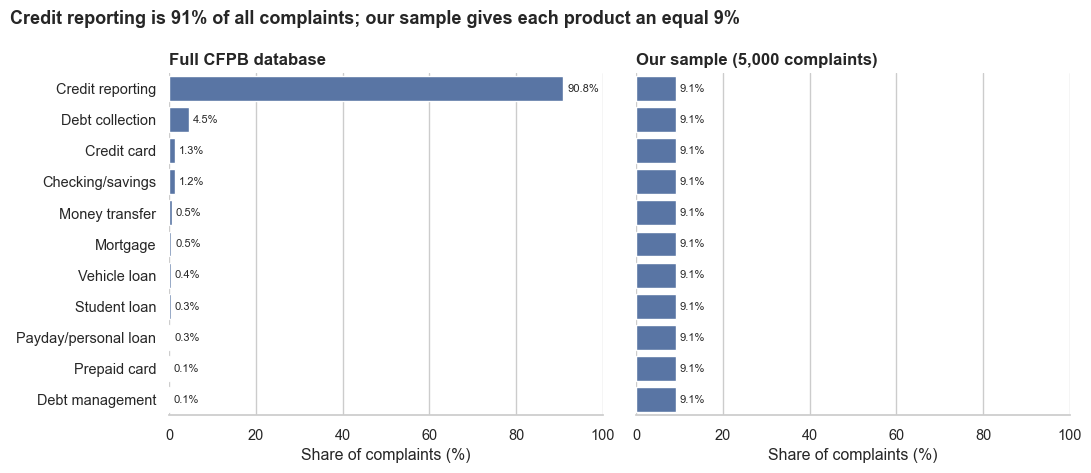

In [12]:
# Product counts shown on the CFPB complaint search page (all complaints, Oct 2026)
database_counts = pd.Series({
    "Credit reporting": 6_341_482, "Debt collection": 317_439, "Credit card": 92_750,
    "Checking/savings": 85_931, "Money transfer": 38_217, "Mortgage": 32_110,
    "Vehicle loan": 24_617, "Student loan": 19_519, "Payday/personal loan": 17_907,
    "Prepaid card": 6_122, "Debt management": 4_243,
})
database_share = database_counts / database_counts.sum() * 100
sample_share = df["product_short"].value_counts(normalize=True) * 100

order = database_share.sort_values().index      # same product order in both panels

shares = pd.DataFrame({"Full CFPB database": database_share,
                       "Our sample (5,000 complaints)": sample_share}).reindex(order[::-1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, column in zip(axes, shares.columns):
    sns.barplot(x=shares[column], y=shares.index, color=MAIN, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
    ax.set(xlim=(0, 100), xlabel="Share of complaints (%)", ylabel="", title=column)

fig.suptitle("Credit reporting is 91% of all complaints; our sample gives each product an equal 9%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- The real complaint stream is extremely imbalanced: credit reporting is about 91%, and the five smallest products are each under 0.5%. A model trained on raw data could score 91% accuracy by always guessing "credit reporting" and still be useless for routing.
- Our sample has about 455 complaints per product, so **accuracy is a fair headline metric**, and **macro F1** (which weights every product equally) shows whether small products are handled well.
- For Phase 3: a model trained on balanced data will over-predict small products when used on real traffic. We will note this and consider adjusting for real-world frequencies when interpreting results.

### 1.4 Coverage over time

In [13]:
per_month = df["month"].value_counts().sort_index()
print(per_month.to_string())
print(f"\nSmallest product-month cell: {pd.crosstab(df['month'], df['Product']).min().min()} complaints")

month
2025-08    418
2025-09    418
2025-10    418
2025-11    418
2025-12    418
2026-01    418
2026-02    418
2026-03    418
2026-04    418
2026-05    418
2026-06    413
2026-07    407
Freq: M

Smallest product-month cell: 37 complaints


- Every month has about 418 complaints (July is slightly lower because the CFPB stopped publishing narratives in August 2026), and every product appears in every month. Any pattern we find is not driven by one unusual month.

### 1.5 Text length

The narrative length tells us how much signal each complaint carries.

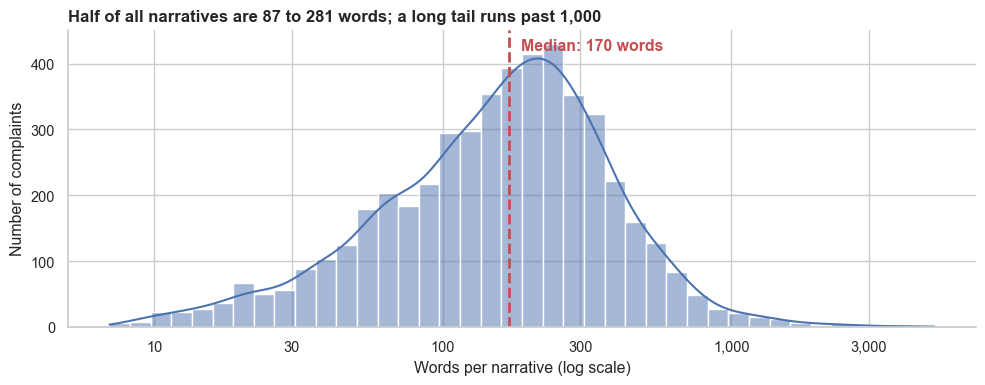

count    5000.0
mean      225.0
std       251.0
min         7.0
25%        87.0
50%       170.0
75%       281.0
max      5058.0
Under 50 words: 12%   Over 500 words: 7%


In [14]:
words = df["word_count"]
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(words, bins=40, log_scale=True, color=MAIN, kde=True, ax=ax)   # log scale: lengths are very skewed
ax.axvline(words.median(), color=ACCENT, linewidth=2, linestyle="--")
ax.text(words.median() * 1.1, ax.get_ylim()[1] * 0.93, f"Median: {words.median():.0f} words",
        color=ACCENT, fontweight="bold")
ax.set_xticks([10, 30, 100, 300, 1000, 3000], labels=["10", "30", "100", "300", "1,000", "3,000"])
ax.set(xlabel="Words per narrative (log scale)", ylabel="Number of complaints",
       title="Half of all narratives are 87 to 281 words; a long tail runs past 1,000")
sns.despine()
plt.tight_layout()
plt.show()

print(words.describe().round(0).to_string())
print(f"Under 50 words: {(words < 50).mean():.0%}   Over 500 words: {(words > 500).mean():.0%}")

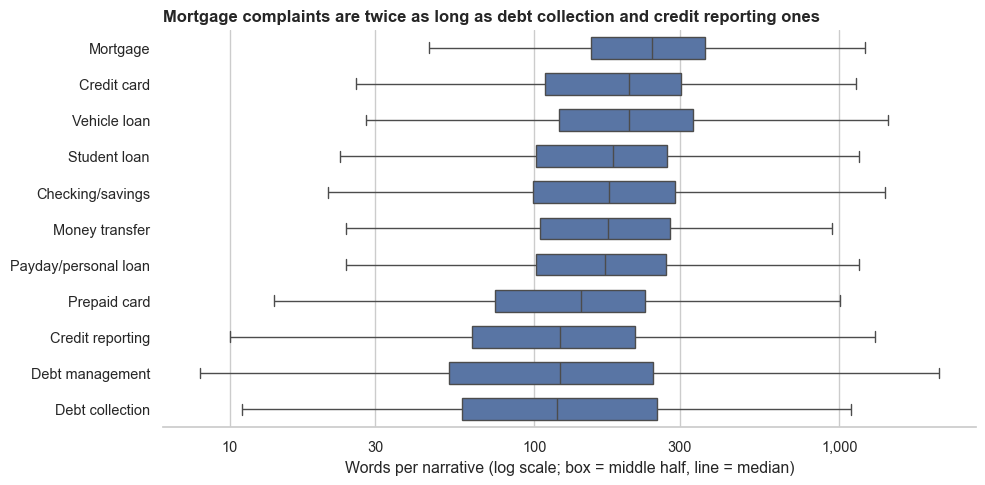

In [15]:
# Narrative length by product
# One box per product; sorted longest to shortest by median word count

# Product names ordered by median word count (longest first)
order_by_median = df.groupby("product_short")["word_count"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 5))

# Box = middle 50% of complaints, line = median; log scale because a few narratives run past 5,000 words
sns.boxplot(data=df, x="word_count", y="product_short", order=order_by_median,
            color=MAIN, log_scale=True, showfliers=False, width=0.6, ax=ax)   # showfliers=False hides outlier dots

# Plain-number tick labels instead of 10^1, 10^2 on the log axis
ax.set_xticks([10, 30, 100, 300, 1000], labels=["10", "30", "100", "300", "1,000"])

# Axis labels and a title that states the finding
ax.set(xlabel="Words per narrative (log scale; box = middle half, line = median)", ylabel="",
       title="Mortgage complaints are twice as long as debt collection and credit reporting ones")

sns.despine(left=True)   # remove border lines for a cleaner look
plt.tight_layout()       # keep labels from being cut off
plt.show()

- The typical complaint is about 170 words, a solid paragraph, which is plenty of text for a word-based (TF-IDF) model.
- Length differs by product: mortgage narratives (median 244 words) are about twice as long as debt collection or credit reporting (about 120). Longer stories carry more product-specific detail, so mortgage should be easier to classify.
- The boxes overlap heavily, so **length alone cannot tell products apart**; the model has to rely on the words used.
- The short end matters too: 12% of narratives are under 50 words. Short credit reporting and debt collection complaints are the ones most likely to be confused with each other, which we will check in the confusion matrix in Phase 3.

### 1.6 Data quality: redactions and template letters

In [16]:
has_redaction = df[TEXT_COL].str.contains(r"X{2,}")
print(f"Narratives with redacted text (XXXX): {has_redaction.mean():.0%}")

dupes = duplicate_narratives(df)
extra_copies = int((dupes["copies"] - 1).sum())
print(f"Narratives that appear more than once: {len(dupes)}  ({extra_copies} extra copies)")
dupes.head(5)

Narratives with redacted text (XXXX): 82%
Narratives that appear more than once: 44  (105 extra copies)


,copies,narrative_start
0,27,There are collection accounts on my report that I believe contain inaccurate information. Under my rights pursuant to 15...
1,13,"You have reported inaccurate and unauthorized accounts on my credit report, which is a violation of the Fair Credit Repo..."
2,7,My rights were violated as a consumer under 15USC1681B and I need them blocked and deleted from my report ASAP...
3,7,I want to stress that I did not give written permission for these specific transactions to be included in my consumer re...
4,5,My credit reports are inaccurate. These inaccuracies are causing creditors to deny me credit. You have the duty to repor...


- **82% of narratives contain CFPB redactions** (`XXXX` for names, account numbers and dates). These are meaningless to a model, so the cleaning step will remove them before counting words.
- **105 rows are exact copies** of 44 template letters, mostly credit reporting disputes citing FCRA sections. If copies land in both the training and test sets, the model is tested on text it has already seen and its score is inflated. We remove the extra copies before modeling, leaving 4,895 unique narratives.

### 1.7 Example narratives (one per product)

In [17]:
examples = (df.groupby("product_short")
              .sample(1, random_state=7)[["product_short", TEXT_COL]]
              .set_index("product_short"))
examples[TEXT_COL] = examples[TEXT_COL].str.slice(0, 250) + "..."
examples

,Consumer complaint narrative
product_short,
Checking/savings,On XX/XX/year> I have requested my bank that someone has hacked my online account and transferred funds using XXXX. There are total of 18 Transactions which i have reported as fraud. As of Today m...
Credit card,"In XX/XX/XXXX, I opened an XXXX XXXX credit card with XXXX in good faith. In XX/XX/XXXX, XXXX unilaterally migrated its co-branded portfolio to Citibank. Because I already hold an identical XXXX X..."
Credit reporting,My report includes inquiries that I believe do not meet the permissible purpose requirement set forth in 15 USC 1681b. I suspect these inquiries were made in error and am requesting their removal....
Debt collection,"I am disputing the balance of {$9400.00} that National Credit Systems , Inc. ( XXXX Account # XXXX ) is attempting to collect on behalf of XXXX XXXX XXXX in XXXX XXXX, Missouri ( Unit XXXX, Client..."
Debt management,"This is a formal and unequivocal demand for immediate investigation and removal of the following inaccurate and defamatory tradelines from my credit file. Under FCRA XXXX ( b ) and 15 U.S.C. XXXX,..."
Money transfer,Venmo issued a refund on XX/XX/year> to a closed debit card. Neither I nor my bank XXXX XXXX XXXX XXXX ) have any record of receiving these funds. XXXX has failed to provide an XXXX XXXX XXXX ( XX...
Mortgage,"In XX/XX/XXXX, I submitted a Qualified Written Request ( QWR ) to the current servicer, requesting complete payoff, servicing, and custodial documentation for XXXX NationPoint/National City mortga..."
Payday/personal loan,I lost my job unexpectedly after nearly 8 years with my former employer and immediately reached out to Check Advance USA to request a one-time hardship settlement. Ive already made two large payme...
Prepaid card,"Complaint Against : American Express XXXX XXXX XXXX On XX/XX/year>, I contacted American Express XXXX XXXX XXXX regarding a {$50.00} gift card my XXXX daughter received for XXXX from her grandmoth..."


- Many narratives name the product outright ("my mortgage", "my credit card"), which makes classification easier but raises a validity question: is the model learning the problem, or just spotting product names? Section 2 measures how often product words appear, and Phase 3 will test the model with those words masked.